# Bài thực hành 4: K láng giềng gần nhất

**Sinh viên:** Nguyễn Thành Phong · **Học phần:** Học máy ứng dụng · **Giảng viên:** ThS. Nguyễn Thái Anh

Dữ liệu (số liệu mô phỏng dùng cho giảng dạy):
- `data/sinh_vien_mo_rong.csv`: 120 sinh viên, 4 cột `gio_on`, `diem_giua_ky`, `chi_tieu` (nghìn đồng/tháng), `qua_mon`.
- `data/hai_vang_trang.csv`: 300 điểm, 3 cột `x1`, `x2`, `nhan`, hai lớp nằm trên hai vầng trăng lồng nhau.
- `data/gia_nha.csv`: dùng lại từ bài 1, 60 căn nhà, 4 cột `dien_tich`, `so_phong`, `tuoi_nha`, `gia` (tỷ đồng).

Mỗi mục bên dưới ứng với một tệp trong `code/` (phần bài giảng) hoặc `baitap04/` (phần bài tập).
Chạy các tệp đó từ thư mục `Lab04/`, ví dụ `python baitap04/bai1.py`.

In [1]:
# Chuẩn bị dữ liệu: chạy local thì đọc thẳng, trên Colab thì tải ba tệp lên
import os
CAN_CO = ["data/sinh_vien_mo_rong.csv", "data/hai_vang_trang.csv", "data/gia_nha.csv"]
if not all(os.path.exists(p) for p in CAN_CO):
    from google.colab import files
    files.upload()                         # chon ca ba tep csv
    os.makedirs("data", exist_ok=True)
    for p in CAN_CO:
        if os.path.exists(os.path.basename(p)):
            os.replace(os.path.basename(p), p)
for p in CAN_CO:
    print(f"Co {p} chua?", os.path.exists(p))

Co data/sinh_vien_mo_rong.csv chua? True
Co data/hai_vang_trang.csv chua? True
Co data/gia_nha.csv chua? True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Hai màu cố định cho hai lớp, dùng chung cho mọi hình
MAU_1 = "#2a78d6"          # qua môn / nhãn 1
MAU_0 = "#eb6834"          # rớt môn / nhãn 0
MAU_CHU = "#52514e"
NEN = ["#fbe1d6", "#d6e6f8"]   # nền vùng quyết định của lớp 0 và lớp 1
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MAU_CHU, "axes.grid": True, "grid.color": "#e4e3df",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "lines.linewidth": 2,
})


def ve_bien(ax, mo_hinh, X, y, ten_cot, khung, n=300):
    """Ve vung quyet dinh cua mo_hinh va cac diem du lieu (hai lop 0 / 1)."""
    (x0, x1), (y0, y1) = khung
    gx, gy = np.meshgrid(np.linspace(x0, x1, n), np.linspace(y0, y1, n))
    luoi = pd.DataFrame({ten_cot[0]: gx.ravel(), ten_cot[1]: gy.ravel()})
    vung = mo_hinh.predict(luoi).reshape(gx.shape)
    ax.contourf(gx, gy, vung, levels=[-0.5, 0.5, 1.5], colors=NEN)
    ax.contour(gx, gy, vung, levels=[0.5], colors=MAU_CHU, linewidths=1.2)
    for nhan, mau, mk in [(1, MAU_1, "o"), (0, MAU_0, "^")]:
        nhom = X[y == nhan]
        ax.scatter(nhom[ten_cot[0]], nhom[ten_cot[1]], c=mau, marker=mk, s=22,
                   edgecolor="white", linewidth=0.6)
    ax.grid(False)

## 1. Khoảng cách và láng giềng (`code/e1_khoang_cach.py`)

$$d(\mathbf{x}, \mathbf{z}) = \sqrt{(x_1 - z_1)^2 + (x_2 - z_2)^2 + \dots + (x_d - z_d)^2}$$

In [3]:
import numpy as np
import pandas as pd

# Ba bạn: A và C học gần như y hệt nhau, B học khác hẳn
ba_ban = {
    "A": np.array([5.0, 3.0, 4000.0]),
    "B": np.array([25.0, 9.0, 4100.0]),
    "C": np.array([6.0, 3.5, 7000.0]),
}


def kc(u, v):
    """Khoang cach Euclid giua hai diem."""
    return np.sqrt(((u - v) ** 2).sum())


print("Khoang cach KHI CHUA chuan hoa")
print(f"  d(A, B) = {kc(ba_ban['A'], ba_ban['B']):8.1f}")
print(f"  d(A, C) = {kc(ba_ban['A'], ba_ban['C']):8.1f}")
print()

# Chuẩn hoá bằng trung bình và độ lệch chuẩn của cả bộ dữ liệu
df = pd.read_csv("data/sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]].to_numpy(dtype=float)
tb = X.mean(axis=0)
dl = X.std(axis=0)
print("Do lech chuan cua ba cot:")
print(f"  gio_on {dl[0]:.2f}   diem_giua_ky {dl[1]:.2f}"
      f"   chi_tieu {dl[2]:.0f}")
print()

chuan = {ten: (v - tb) / dl for ten, v in ba_ban.items()}
print("Khoang cach SAU KHI chuan hoa")
print(f"  d(A, B) = {kc(chuan['A'], chuan['B']):.2f}")
print(f"  d(A, C) = {kc(chuan['A'], chuan['C']):.2f}")
print()

# Tìm 5 láng giềng gần nhất của một bạn mới, chỉ dùng hai cột học tập
X2 = df[["gio_on", "diem_giua_ky"]].to_numpy(dtype=float)
y = df["qua_mon"].to_numpy()
tb2, dl2 = X2.mean(axis=0), X2.std(axis=0)
ban_moi = np.array([12.0, 6.5])
X2c = (X2 - tb2) / dl2
moi_c = (ban_moi - tb2) / dl2
khoang = np.sqrt(((X2c - moi_c) ** 2).sum(axis=1))
gan = np.argsort(khoang)[:5]

print("Ban moi: on 12 gio, diem giua ky 6.5")
print("Nam lang gieng gan nhat:")
for i in gan:
    ket = "qua" if y[i] == 1 else "rot"
    print(f"  gio {X2[i, 0]:5.1f}  diem {X2[i, 1]:4.1f}  "
          f"khoang cach {khoang[i]:.3f}  -> {ket}")
so_qua = int(y[gan].sum())
print(f"Bo phieu: {so_qua} qua, {5 - so_qua} rot")
print("Du doan:", "qua mon" if so_qua >= 3 else "rot mon")

Khoang cach KHI CHUA chuan hoa
  d(A, B) =    102.2
  d(A, C) =   3000.0

Do lech chuan cua ba cot:
  gio_on 7.82   diem_giua_ky 2.09   chi_tieu 1692

Khoang cach SAU KHI chuan hoa
  d(A, B) = 3.85
  d(A, C) = 1.79

Ban moi: on 12 gio, diem giua ky 6.5
Nam lang gieng gan nhat:
  gio  10.5  diem  6.4  khoang cach 0.198  -> qua
  gio  12.5  diem  6.1  khoang cach 0.202  -> qua
  gio  14.0  diem  6.4  khoang cach 0.260  -> qua
  gio   9.5  diem  6.1  khoang cach 0.373  -> rot
  gio  10.5  diem  5.8  khoang cach 0.386  -> qua
Bo phieu: 4 qua, 1 rot
Du doan: qua mon


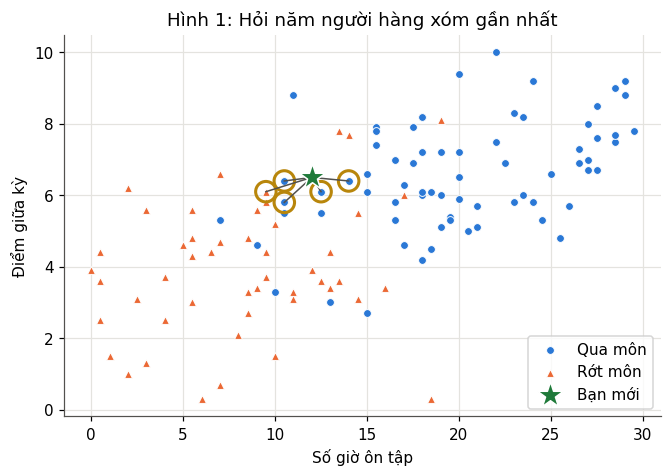

In [4]:
# Hình 1: bạn mới (ngôi sao) và năm láng giềng gần nhất, khoảng cách tính sau chuẩn hoá
fig, ax = plt.subplots(figsize=(7, 4.5))
for nhan, mau, mk, ten in [(1, MAU_1, "o", "Qua môn"), (0, MAU_0, "^", "Rớt môn")]:
    nhom = df[df["qua_mon"] == nhan]
    ax.scatter(nhom["gio_on"], nhom["diem_giua_ky"], c=mau, marker=mk, s=26,
               edgecolor="white", linewidth=0.6, label=ten)
for i in gan:
    ax.plot([ban_moi[0], X2[i, 0]], [ban_moi[1], X2[i, 1]], color=MAU_CHU, lw=1)
    ax.scatter(X2[i, 0], X2[i, 1], s=180, facecolor="none", edgecolor="#b8860b", lw=2)
ax.scatter(*ban_moi, marker="*", s=320, c="#1f7a3a", edgecolor="white", zorder=5, label="Bạn mới")
ax.set_xlabel("Số giờ ôn tập"); ax.set_ylabel("Điểm giữa kỳ")
ax.set_title("Hình 1: Hỏi năm người hàng xóm gần nhất"); ax.legend(loc="lower right")
plt.show()

**Nhận xét.** Kết quả khớp tài liệu từng con số. Bạn A và bạn C ôn bài gần như giống nhau (5 và 6 giờ, điểm 3.0 và 3.5), chỉ khác tiền chi tiêu. Khi chưa chuẩn hoá thì d(A, C) = 3000.0, lớn gấp gần 30 lần d(A, B) = 102.2, nên máy coi A giống B hơn, chỉ vì A và B tiêu tiền gần bằng nhau. Độ lệch chuẩn của cột chi tiêu là 1692, của giờ ôn là 7.82 và của điểm là 2.09. Chênh 3000 nghìn đồng vì thế đè bẹp chênh 20 giờ ôn. Sau chuẩn hoá, mỗi cột được đo bằng độ lệch chuẩn của chính nó: d(A, C) = 1.79 < d(A, B) = 3.85, đúng như trực giác.

Năm láng giềng của bạn mới (ôn 12 giờ, điểm 6.5) gồm 4 bạn qua và 1 bạn rớt, nên KNN đoán **qua môn** (Hình 1). Bạn rớt duy nhất ôn 9.5 giờ, điểm 6.1, đứng thứ tư về khoảng cách. Đây là vùng giáp ranh của hai lớp, nên kết luận phụ thuộc khá nhiều vào k.

## 2. Chuẩn hoá, bước không được bỏ qua (`code/e2_chuan_hoa.py`)

$$x' = \frac{x - \text{trung bình}}{\text{độ lệch chuẩn}}$$

In [5]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_mo_rong.csv")
y = df["qua_mon"]

X3 = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
X_tr, X_te, y_tr, y_te = train_test_split(
    X3, y, test_size=0.25, random_state=17, stratify=y
)


def cham(mo_hinh, cot):
    mo_hinh.fit(X_tr[cot], y_tr)
    return accuracy_score(y_te, mo_hinh.predict(X_te[cot]))


def knn_chuan():
    """KNN co chuan hoa, gop lam mot khoi bang pipeline."""
    return make_pipeline(StandardScaler(), KNeighborsClassifier(7))


ba_cot = ["gio_on", "diem_giua_ky", "chi_tieu"]
hai_cot = ["gio_on", "diem_giua_ky"]

a = cham(KNeighborsClassifier(n_neighbors=7), ba_cot)
b = cham(knn_chuan(), ba_cot)
c = cham(knn_chuan(), hai_cot)

print(f"Doan bua ca lop qua          : {y_te.mean():.4f}")
print(f"Ba cot, khong chuan hoa      : {a:.4f}")
print(f"Ba cot, co chuan hoa         : {b:.4f}")
print(f"Bo cot chi_tieu, co chuan hoa: {c:.4f}")

Doan bua ca lop qua          : 0.6000
Ba cot, khong chuan hoa      : 0.5333
Ba cot, co chuan hoa         : 0.8667
Bo cot chi_tieu, co chuan hoa: 0.9000


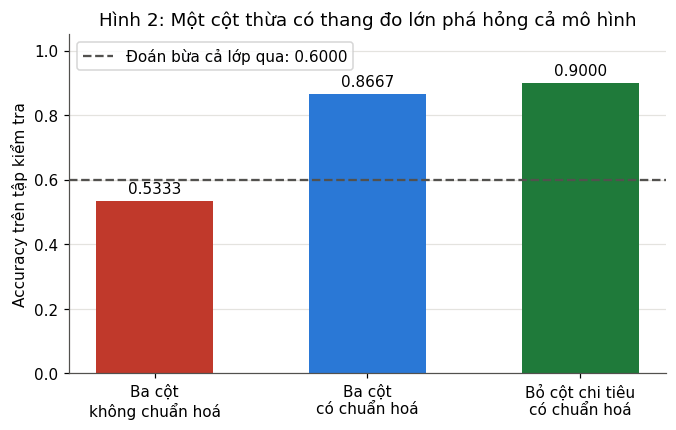

In [6]:
# Hình 2: accuracy trên tập kiểm tra theo ba cách đưa dữ liệu vào KNN
fig, ax = plt.subplots(figsize=(7, 4))
nhan_cot = ["Ba cột\nkhông chuẩn hoá", "Ba cột\ncó chuẩn hoá", "Bỏ cột chi tiêu\ncó chuẩn hoá"]
cot = ax.bar(nhan_cot, [a, b, c], width=0.55, color=["#c0392b", MAU_1, "#1f7a3a"])
ax.bar_label(cot, fmt="%.4f", padding=3)
ax.axhline(y_te.mean(), ls="--", color=MAU_CHU, lw=1.5, label=f"Đoán bừa cả lớp qua: {y_te.mean():.4f}")
ax.set_ylim(0, 1.05); ax.set_ylabel("Accuracy trên tập kiểm tra"); ax.grid(axis="x", visible=False)
ax.set_title("Hình 2: Một cột thừa có thang đo lớn phá hỏng cả mô hình"); ax.legend(loc="upper left")
plt.show()

**Nhận xét.** Khớp tài liệu: không chuẩn hoá chỉ đạt 0.5333, thấp hơn cả mức đoán bừa 0.6000 (luôn đoán qua). Có chuẩn hoá thì lên 0.8667, và bỏ hẳn cột chi tiêu rồi chuẩn hoá thì đạt 0.9000 (Hình 2).

Khi chưa chuẩn hoá, khoảng cách gần như chỉ là chênh lệch chi tiêu, nên KNN đang hỏi "bạn nào tiêu tiền giống mình nhất". Câu hỏi đó không liên quan gì tới việc qua môn, và kết quả còn tệ hơn đoán bừa. Sau chuẩn hoá, chi tiêu nặng ngang hai cột kia nhưng vẫn chỉ là nhiễu, nên bỏ nó đi lại tốt hơn. Hai bài học: chuẩn hoá là bắt buộc, và chọn đúng cột cũng quan trọng như chuẩn hoá.

`make_pipeline(StandardScaler(), KNeighborsClassifier(7))` tính trung bình và độ lệch chuẩn **chỉ trên tập học** khi `.fit`, rồi dùng lại đúng hai con số đó khi `.predict`. Nhờ vậy tập kiểm tra không rò thông tin vào bước chuẩn hoá.

## 3. Chọn số láng giềng (`code/e3_chon_k.py`)

In [7]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Hai cột x1 và x2 có thang đo gần nhau, độ lệch chuẩn chỉ chênh khoảng
# 1.6 lần, nên ở bộ này không chuẩn hoá cũng được.
print("Accuracy tren tap hoc va tap kiem tra theo k")
print("    k    tap hoc   tap kiem tra")
for k in [1, 5, 13, 31, 101]:
    mh = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {k:3d}   {a_hoc:.4f}     {a_kt:.4f}")
print()

# Chọn k chỉ dựa trên tập học, không nhìn tập kiểm tra
print("Kiem dinh cheo 5 phan tren tap hoc:")
diem = {}
for k in range(1, 52, 2):
    diem[k] = cross_val_score(KNeighborsClassifier(n_neighbors=k),
                              X_tr, y_tr, cv=5).mean()
k_tot = max(diem, key=diem.get)
for k in [1, 5, 9, 13, 17, 25, 51]:
    dau = "  <- tot nhat" if k == k_tot else ""
    print(f"  k = {k:2d}  diem trung binh {diem[k]:.4f}{dau}")
print()

# Chọn xong mới mở tập kiểm tra, và chỉ mở một lần
mh = KNeighborsClassifier(n_neighbors=k_tot).fit(X_tr, y_tr)
print(f"k tot nhat = {k_tot}")
acc = accuracy_score(y_te, mh.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

Accuracy tren tap hoc va tap kiem tra theo k
    k    tap hoc   tap kiem tra
    1   1.0000     0.8000
    5   0.8756     0.9067
   13   0.8844     0.9200


   31   0.8667     0.8933
  101   0.8311     0.8533

Kiem dinh cheo 5 phan tren tap hoc:


  k =  1  diem trung binh 0.7778
  k =  5  diem trung binh 0.8444
  k =  9  diem trung binh 0.8444
  k = 13  diem trung binh 0.8667  <- tot nhat
  k = 17  diem trung binh 0.8533
  k = 25  diem trung binh 0.8622
  k = 51  diem trung binh 0.8533

k tot nhat = 13
Accuracy tren tap kiem tra = 0.9200


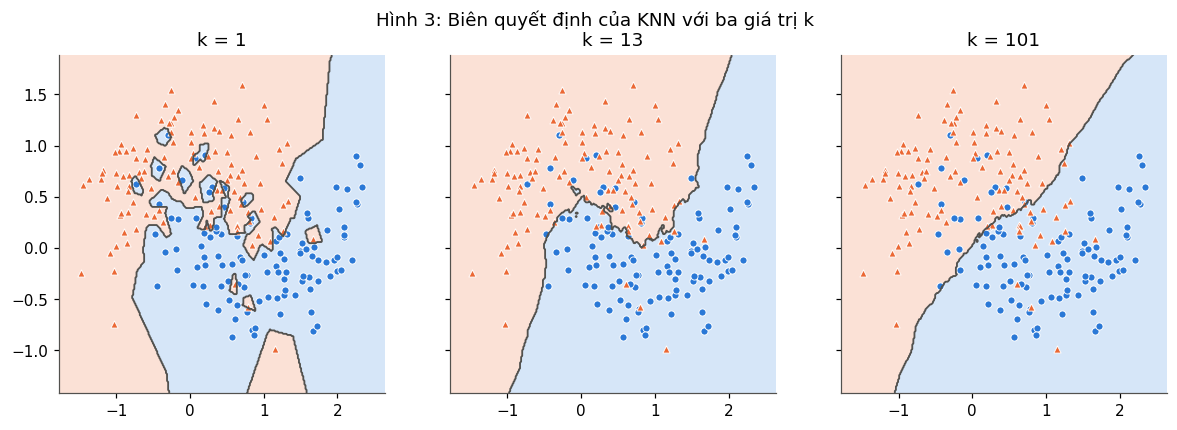

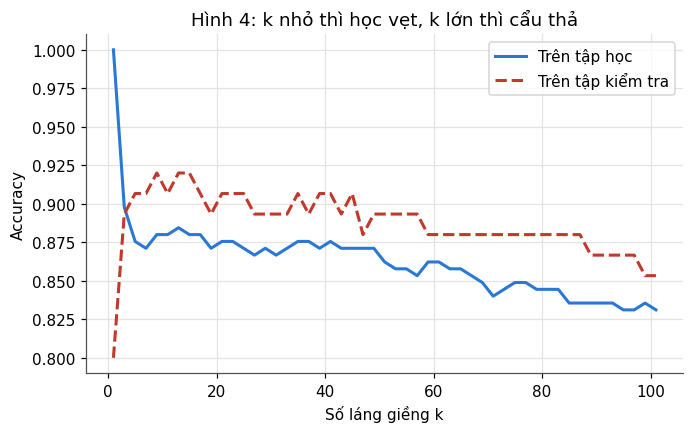

In [8]:
# Hình 3: biên quyết định với k = 1, 13, 101 trên bộ hai vầng trăng
khung = ((X["x1"].min() - 0.3, X["x1"].max() + 0.3), (X["x2"].min() - 0.3, X["x2"].max() + 0.3))
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, k in zip(axs, [1, 13, 101]):
    m = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    ve_bien(ax, m, X_tr, y_tr, ["x1", "x2"], khung)
    ax.set_title(f"k = {k}")
fig.suptitle("Hình 3: Biên quyết định của KNN với ba giá trị k"); plt.show()

# Hình 4: accuracy trên tập học và tập kiểm tra khi k chạy từ 1 tới 101
cac_k = list(range(1, 102, 2))
hoc, kt = [], []
for k in cac_k:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    hoc.append(accuracy_score(y_tr, m.predict(X_tr)))
    kt.append(accuracy_score(y_te, m.predict(X_te)))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cac_k, hoc, color=MAU_1, label="Trên tập học")
ax.plot(cac_k, kt, "--", color="#c0392b", label="Trên tập kiểm tra")
ax.set_xlabel("Số láng giềng k"); ax.set_ylabel("Accuracy")
ax.set_title("Hình 4: k nhỏ thì học vẹt, k lớn thì cẩu thả"); ax.legend()
plt.show()

**Nhận xét.** Khớp tài liệu. Với k = 1, accuracy trên tập học là 1.0000 nhưng trên tập kiểm tra chỉ 0.8000. Mỗi điểm của tập học là láng giềng gần nhất của chính nó nên luôn tự bỏ phiếu đúng cho mình, và con số 1.0000 đó không nói lên điều gì. Hình 3 cho thấy biên của k = 1 gập ghềnh bám theo từng điểm nhiễu (học vẹt). Biên của k = 13 cong mềm theo hai vầng trăng. Biên của k = 101 gần như một đường thẳng chéo, tức mô hình cẩu thả: mỗi điểm hỏi tới 101 trong 225 điểm của tập học.

Kiểm định chéo 5 phần chỉ dùng tập học và chọn k = 13 với điểm 0.8667. Chọn xong mới chấm tập kiểm tra một lần, được 0.9200. Bảng đầu tiên cũng cho thấy k = 13 tốt nhất trên tập kiểm tra, nhưng nếu chọn k bằng cách nhìn bảng đó thì 0.9200 không còn là điểm của một bài thi chưa từng thấy. Hình 4: đường tập học đi xuống khi k tăng, đường tập kiểm tra lên nhanh rồi giảm dần sau k khoảng 15. Chỉ thử k lẻ để hai lớp không bao giờ hoà phiếu.

## 4. So với các mô hình đã học (`code/e4_so_sanh.py`)

In [9]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cac_mo_hinh = [
    ("Hoi quy logistic", LogisticRegression()),
    ("Naive Bayes     ", GaussianNB()),
    ("KNN, k = 13     ", KNeighborsClassifier(n_neighbors=13)),
]

print("Accuracy tren tap kiem tra, bo hai vang trang")
for ten, mh in cac_mo_hinh:
    mh.fit(X_tr, y_tr)
    print(f"  {ten}: {accuracy_score(y_te, mh.predict(X_te)):.4f}")

Accuracy tren tap kiem tra, bo hai vang trang
  Hoi quy logistic: 0.8533
  Naive Bayes     : 0.8533
  KNN, k = 13     : 0.9200


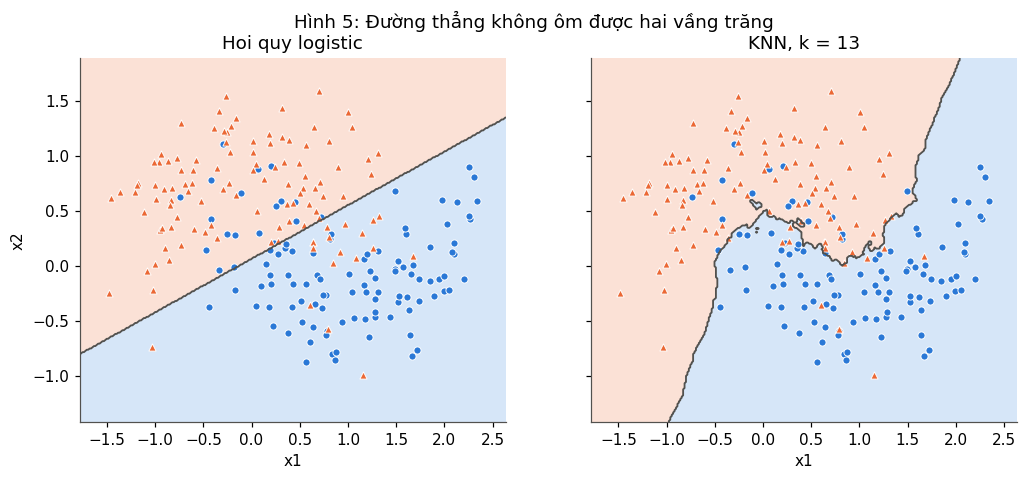

So chieu  gan nhat / xa nhat
     1     0.001
     2     0.016
     5     0.145
    10     0.280
    20     0.448
    50     0.611
   100     0.715
   500     0.861


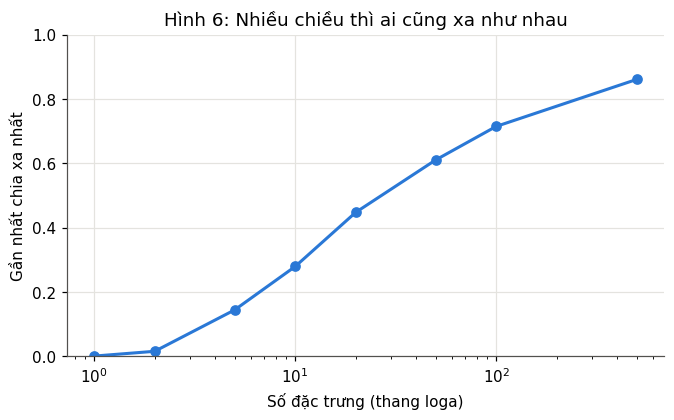

In [10]:
# Hình 5: biên quyết định của hồi quy logistic và của KNN với k = 13
khung = ((X["x1"].min() - 0.3, X["x1"].max() + 0.3), (X["x2"].min() - 0.3, X["x2"].max() + 0.3))
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, (ten, mh) in zip(axs, [cac_mo_hinh[0], cac_mo_hinh[2]]):
    ve_bien(ax, mh, X_tr, y_tr, ["x1", "x2"], khung)
    ax.set_title(ten.strip()); ax.set_xlabel("x1")
axs[0].set_ylabel("x2")
fig.suptitle("Hình 5: Đường thẳng không ôm được hai vầng trăng"); plt.show()

# Hình 6: tỷ số khoảng cách gần nhất / xa nhất khi số chiều tăng (500 điểm ngẫu nhiên)
rng = np.random.default_rng(0)
so_chieu = [1, 2, 5, 10, 20, 50, 100, 500]
ty_so = []
for d in so_chieu:
    diem = rng.random((500, d))
    hoi = rng.random((20, d))                       # 20 điểm hỏi, lấy trung bình
    kc_ = np.sqrt(((hoi[:, None, :] - diem[None, :, :]) ** 2).sum(axis=2))
    ty_so.append((kc_.min(axis=1) / kc_.max(axis=1)).mean())
print("So chieu  gan nhat / xa nhat")
for d, t in zip(so_chieu, ty_so):
    print(f"  {d:4d}     {t:.3f}")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(so_chieu, ty_so, "o-", color=MAU_1)
ax.set_xscale("log"); ax.set_ylim(0, 1)
ax.set_xlabel("Số đặc trưng (thang loga)"); ax.set_ylabel("Gần nhất chia xa nhất")
ax.set_title("Hình 6: Nhiều chiều thì ai cũng xa như nhau"); plt.show()

**Nhận xét.** Khớp tài liệu: hồi quy logistic và Naive Bayes cùng đạt 0.8533, KNN với k = 13 đạt 0.9200. Hình 5 cho thấy lý do. Hồi quy logistic chỉ vẽ được một đường thẳng nên cắt ngang hai vầng trăng và chấp nhận sai ở hai đầu mũi. KNN không giả định biên có hình gì (mô hình **không tham số**) nên uốn theo dữ liệu.

Cái giá là lời nguyền số chiều (Hình 6). Với 2 đặc trưng, khoảng cách tới láng giềng gần nhất chỉ bằng khoảng 0.02 lần khoảng cách tới điểm xa nhất. Với 500 đặc trưng, tỷ số đó lên 0.86, nghĩa là láng giềng gần nhất cũng xa gần bằng điểm xa nhất, và việc hỏi hàng xóm không còn ý nghĩa. Tài liệu không nêu cách đo; ở đây lấy trung bình trên 20 điểm hỏi, được 0.016 với 2 chiều và 0.861 với 500 chiều, cùng độ lớn với tài liệu (0.01 và 0.86). KNN vì vậy hợp với bài toán ít đặc trưng.

## 5. KNN cho bài toán hồi quy (`code/e5_knn_hoi_quy.py`)

In [11]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# Cùng cách chia với bài 1 để so sánh công bằng
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42)

knn = KNeighborsRegressor(n_neighbors=5).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print("MAE tren tap kiem tra (ty dong)")
mae_knn = mean_absolute_error(y_te, knn.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f"  KNN, k = 5  : {mae_knn:.4f}")
print(f"  Duong thang : {mae_duong:.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print("  dien tich     KNN   duong thang")
for dt, a, b in zip(can_moi["dien_tich"], knn.predict(can_moi),
                    duong.predict(can_moi)):
    print(f"    {dt:6.0f} m2   {a:6.2f}    {b:6.2f}")
print()

# Năm láng giềng của căn 250 m2 chính là những căn rộng nhất đã thấy
_, chi_so = knn.kneighbors(pd.DataFrame({"dien_tich": [250.0]}))
lg = X_tr.iloc[chi_so[0]]["dien_tich"].tolist()
print("Nam lang gieng cua can 250 m2:", ", ".join(f"{v:.1f}" for v in lg))

MAE tren tap kiem tra (ty dong)
  KNN, k = 5  : 0.4030
  Duong thang : 0.2578

Du doan cho bon can moi (ty dong)
  dien tich     KNN   duong thang
        60 m2     4.95      5.12
       100 m2     8.32      8.24
       150 m2     9.32     12.13
       250 m2     9.32     19.91

Nam lang gieng cua can 250 m2: 117.5, 115.9, 111.7, 111.2, 104.2


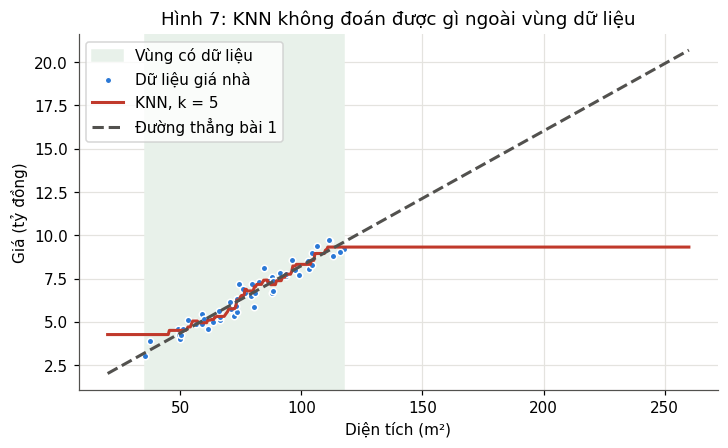

In [12]:
# Hình 7: đường dự đoán của KNN và của đường thẳng bài 1
xs = pd.DataFrame({"dien_tich": np.linspace(20, 260, 500)})
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.axvspan(X["dien_tich"].min(), X["dien_tich"].max(), color="#e8f1ea", label="Vùng có dữ liệu")
ax.scatter(X["dien_tich"], y, s=18, color=MAU_1, edgecolor="white", label="Dữ liệu giá nhà")
ax.plot(xs["dien_tich"], knn.predict(xs), color="#c0392b", label="KNN, k = 5")
ax.plot(xs["dien_tich"], duong.predict(xs), "--", color=MAU_CHU, label="Đường thẳng bài 1")
ax.set_xlabel("Diện tích (m²)"); ax.set_ylabel("Giá (tỷ đồng)")
ax.set_title("Hình 7: KNN không đoán được gì ngoài vùng dữ liệu"); ax.legend(loc="upper left")
plt.show()

**Nhận xét.** Khớp tài liệu: trên giá nhà, đường thẳng thắng với MAE 0.2578 tỷ so với 0.4030 tỷ của KNN. Giá trong bộ dữ liệu tăng gần như thẳng theo diện tích, nên giả định đường thẳng là giả định đúng.

Bảng bốn căn mới là chỗ đáng chú ý. Căn 60 m² và 100 m² được hai mô hình đoán gần nhau, nhưng căn 150 m² và căn 250 m² đều được KNN đoán đúng 9.32 tỷ. Năm láng giềng của cả hai căn là năm căn rộng nhất của tập học (104.2 tới 117.5 m²), nên dự đoán là trung bình giá của năm căn đó và không thể vượt ra ngoài. Hình 7 thấy rõ: đường KNN nằm ngang ở hai đầu vùng dữ liệu, còn đường thẳng thì kéo dài mãi (tới 19.91 tỷ cho căn 250 m², cũng không chắc đúng). KNN **không ngoại suy được**.

**Bài học chung:** trên hai vầng trăng KNN thắng vì biên cong, trên giá nhà đường thẳng thắng vì quan hệ thật gần như thẳng. Hình dạng thật của dữ liệu quyết định mô hình nào hợp.

---
# Bài tập

Mã của từng bài nằm trong `baitap04/baiN.py`; ô bên dưới chạy đúng mã đó.

## Bài tập 1: Tự viết KNN không dùng thư viện
Viết hàm `knn_du_doan(X_hoc, y_hoc, x_moi, k)` trả về nhãn dự đoán cho một mẫu mới, dự đoán toàn bộ tập kiểm tra của bộ hai vầng trăng với k = 13, tính accuracy và so với `KNeighborsClassifier`.

In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier


def knn_du_doan(X_hoc, y_hoc, x_moi, k):
    """Tra ve nhan du doan cho mot mau moi.

    X_hoc : mang (n, d) cac mau da biet nhan
    y_hoc : mang (n,) nhan 0 / 1 cua tung mau
    x_moi : mang (d,) mau can doan
    k     : so lang gieng duoc hoi
    """
    khoang = np.sqrt(((X_hoc - x_moi) ** 2).sum(axis=1))
    # kind="stable": hai mẫu cách đều nhau thì mẫu đứng trước được chọn trước,
    # giống cách scikit-learn xử lý chỗ hoà
    gan = np.argsort(khoang, kind="stable")[:k]
    phieu = np.bincount(y_hoc[gan], minlength=2)
    return int(np.argmax(phieu))    # hoà phiếu thì argmax lấy lớp nhỏ hơn


df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]

# Cùng cách chia với e3_chon_k.py để so được với KNeighborsClassifier
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
X_hoc, y_hoc = X_tr.to_numpy(), y_tr.to_numpy()
X_kt = X_te.to_numpy()

K = 13
du_tay = np.array([knn_du_doan(X_hoc, y_hoc, x, K) for x in X_kt])
du_tv = KNeighborsClassifier(n_neighbors=K).fit(X_tr, y_tr).predict(X_te)

print(f"KNN tu viet, k = {K}")
print(f"  Accuracy tu viet              : {accuracy_score(y_te, du_tay):.4f}")
print(f"  Accuracy KNeighborsClassifier: {accuracy_score(y_te, du_tv):.4f}")
print(f"  So mau doan khac nhau         : {(du_tay != du_tv).sum()} / {len(du_tay)}")
print()

# Đi chậm qua một mẫu kiểm tra để thấy ba bước của thuật toán
x0 = X_kt[0]
khoang0 = np.sqrt(((X_hoc - x0) ** 2).sum(axis=1))
gan0 = np.argsort(khoang0, kind="stable")[:K]
print(f"Mau kiem tra dau tien: x1 = {x0[0]:.4f}, x2 = {x0[1]:.4f}, "
      f"nhan that = {y_te.iloc[0]}")
print(f"  {K} lang gieng gan nhat co nhan: {y_hoc[gan0].tolist()}")
print(f"  Bo phieu: {(y_hoc[gan0] == 0).sum()} phieu lop 0, "
      f"{(y_hoc[gan0] == 1).sum()} phieu lop 1 -> doan {du_tay[0]}")
print()

# Kiểm thêm vài giá trị k khác, kể cả k chẵn có thể hoà phiếu
print("  k   tu viet   thu vien   so mau khac")
for k in [1, 4, 5, 13, 31, 101]:
    tay = np.array([knn_du_doan(X_hoc, y_hoc, x, k) for x in X_kt])
    tv = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr).predict(X_te)
    print(f"  {k:3d}  {accuracy_score(y_te, tay):.4f}    "
          f"{accuracy_score(y_te, tv):.4f}     {(tay != tv).sum()}")

KNN tu viet, k = 13
  Accuracy tu viet              : 0.9200
  Accuracy KNeighborsClassifier: 0.9200
  So mau doan khac nhau         : 0 / 75

Mau kiem tra dau tien: x1 = -0.8288, x2 = 0.0701, nhan that = 0
  13 lang gieng gan nhat co nhan: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0]
  Bo phieu: 12 phieu lop 0, 1 phieu lop 1 -> doan 0

  k   tu viet   thu vien   so mau khac
    1  0.8000    0.8000     0
    4  0.9067    0.9067     0
    5  0.9067    0.9067     0
   13  0.9200    0.9200     0
   31  0.8933    0.8933     0
  101  0.8533    0.8533     0


**Nhận xét.** Hàm tự viết đạt accuracy **0.9200**, bằng đúng `KNeighborsClassifier` ở mục 4, và không có mẫu kiểm tra nào bị đoán khác (0/75). Hàm làm đúng ba bước của KNN:
1. `khoang = np.sqrt(((X_hoc - x_moi) ** 2).sum(axis=1))` tính khoảng cách Euclid từ mẫu mới tới **cả 225** mẫu của tập học. Đây là lý do KNN chậm lúc dự đoán.
2. `np.argsort(khoang)[:k]` sắp chỉ số theo khoảng cách tăng dần rồi lấy k mẫu đầu, tức k láng giềng gần nhất.
3. `np.bincount(y_hoc[gan])` đếm phiếu từng lớp, `np.argmax` chọn lớp nhiều phiếu nhất.

Mẫu kiểm tra đầu tiên minh hoạ rõ: trong 13 láng giềng có 12 nhãn 0 và 1 nhãn 1, nên đoán 0, đúng với nhãn thật.

Hai chi tiết để khớp tuyệt đối với thư viện. Thứ nhất, dùng `argsort(kind="stable")`: khi hai mẫu cách đều mẫu mới, mẫu đứng trước trong tập học được chọn trước. Thứ hai, khi hoà phiếu, `argmax` lấy lớp có nhãn nhỏ hơn, giống scikit-learn. Bảng cuối kiểm thêm k = 1, 4, 5, 13, 31, 101, kể cả k = 4 là số chẵn có thể hoà phiếu: mọi trường hợp đều 0 mẫu khác. Vậy KNN của thư viện cũng chỉ làm đúng ba bước này, không có gì "học" thêm lúc `.fit`.

## Bài tập 2: Khoảng cách Manhattan
Chạy lại `e3_chon_k.py` với `metric="manhattan"`, ghi lại k tốt nhất và accuracy trên tập kiểm tra, so với Euclid.

In [14]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def chon_k(metric):
    """Chon k bang kiem dinh cheo 5 phan tren tap hoc, roi cham tap kiem tra."""
    diem = {}
    for k in range(1, 52, 2):
        mh = KNeighborsClassifier(n_neighbors=k, metric=metric)
        diem[k] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    k_tot = max(diem, key=diem.get)
    mh = KNeighborsClassifier(n_neighbors=k_tot, metric=metric).fit(X_tr, y_tr)
    return diem, k_tot, accuracy_score(y_te, mh.predict(X_te))


diem_e, k_e, acc_e = chon_k("euclidean")
diem_m, k_m, acc_m = chon_k("manhattan")

print("Accuracy tren tap hoc va tap kiem tra theo k, khoang cach Manhattan")
print("    k    tap hoc   tap kiem tra")
for k in [1, 5, 13, 31, 101]:
    mh = KNeighborsClassifier(n_neighbors=k, metric="manhattan").fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {k:3d}   {a_hoc:.4f}     {a_kt:.4f}")
print()

print("Kiem dinh cheo 5 phan tren tap hoc:")
print("   k    Euclid   Manhattan")
for k in [1, 5, 9, 13, 17, 25, 51]:
    print(f"  {k:2d}    {diem_e[k]:.4f}   {diem_m[k]:.4f}")
print()

print("Tong ket          k tot nhat   diem KDC   tap kiem tra")
print(f"  Euclid        {k_e:6d}       {diem_e[k_e]:.4f}     {acc_e:.4f}")
print(f"  Manhattan     {k_m:6d}       {diem_m[k_m]:.4f}     {acc_m:.4f}")

Accuracy tren tap hoc va tap kiem tra theo k, khoang cach Manhattan
    k    tap hoc   tap kiem tra
    1   1.0000     0.7867
    5   0.8756     0.8933
   13   0.8667     0.9067
   31   0.8711     0.9067
  101   0.8311     0.8400

Kiem dinh cheo 5 phan tren tap hoc:
   k    Euclid   Manhattan
   1    0.7778   0.7822
   5    0.8444   0.8444
   9    0.8444   0.8222
  13    0.8667   0.8489
  17    0.8533   0.8622
  25    0.8622   0.8578
  51    0.8533   0.8489

Tong ket          k tot nhat   diem KDC   tap kiem tra
  Euclid            13       0.8667     0.9200
  Manhattan         27       0.8667     0.9067


**Nhận xét.** Với khoảng cách Manhattan, kiểm định chéo chọn **k = 27** (điểm 0.8667, bằng đúng điểm tốt nhất của Euclid) và accuracy trên tập kiểm tra là **0.9067**, so với k = 13 và 0.9200 của Euclid. Chênh nhau 0.0133, tức đúng 1 trong 75 mẫu kiểm tra. Bảng theo k cũng chỉ lệch vài phần trăm ở mỗi dòng (ví dụ k = 13: 0.9067 so với 0.9200; k = 101: 0.8400 so với 0.8533).

Từ k = 5 trở đi, điểm kiểm định chéo của hai cách đo dao động quanh nhau trong khoảng 0.82 tới 0.87, và vùng đỉnh rất phẳng. Vì vậy k tốt nhất nhảy từ 13 sang 27 nhưng chất lượng gần như không đổi.

**Một câu:** trên dữ liệu 2 chiều có thang đo gần nhau, đổi từ Euclid sang Manhattan chỉ làm thứ tự vài láng giềng ở rìa thay đổi, nên kết quả gần như không khác; với KNN, chuẩn hoá và chọn k quan trọng hơn nhiều so với chọn công thức khoảng cách.

## Bài tập 3: Đổi đơn vị đo
Đổi `chi_tieu` từ nghìn đồng sang triệu đồng (chia 1000), chạy KNN k = 7 **không chuẩn hoá** trên ba cột; so với 0.5333 ở mục 3, giải thích, và xét trường hợp có chuẩn hoá.

In [15]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_mo_rong.csv")
y = df["qua_mon"]
ba_cot = ["gio_on", "diem_giua_ky", "chi_tieu"]

X_tr, X_te, y_tr, y_te = train_test_split(
    df[ba_cot], y, test_size=0.25, random_state=17, stratify=y
)

# Bản sao đổi chi_tieu sang triệu đồng
X_tr_tr, X_te_tr = X_tr.copy(), X_te.copy()
X_tr_tr["chi_tieu"] = X_tr_tr["chi_tieu"] / 1000
X_te_tr["chi_tieu"] = X_te_tr["chi_tieu"] / 1000


def cham(mo_hinh, X_hoc, X_kt):
    mo_hinh.fit(X_hoc, y_tr)
    return accuracy_score(y_te, mo_hinh.predict(X_kt)), mo_hinh.predict(X_kt)


def knn_tho():
    return KNeighborsClassifier(n_neighbors=7)


def knn_chuan():
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))


print("Do lech chuan cua ba cot tren tap hoc")
print("  don vi          gio_on  diem_giua_ky  chi_tieu")
print(f"  nghin dong    {X_tr.std(ddof=0).iloc[0]:8.2f}  {X_tr.std(ddof=0).iloc[1]:12.2f}"
      f"  {X_tr.std(ddof=0).iloc[2]:8.2f}")
print(f"  trieu dong    {X_tr_tr.std(ddof=0).iloc[0]:8.2f}  {X_tr_tr.std(ddof=0).iloc[1]:12.2f}"
      f"  {X_tr_tr.std(ddof=0).iloc[2]:8.2f}")
print()

a_ng, du_a_ng = cham(knn_tho(), X_tr, X_te)
a_tr, du_a_tr = cham(knn_tho(), X_tr_tr, X_te_tr)
b_ng, du_b_ng = cham(knn_chuan(), X_tr, X_te)
b_tr, du_b_tr = cham(knn_chuan(), X_tr_tr, X_te_tr)
c, _ = cham(knn_chuan(), X_tr[["gio_on", "diem_giua_ky"]],
            X_te[["gio_on", "diem_giua_ky"]])

print("Accuracy tren tap kiem tra, KNN k = 7")
print(f"  Doan bua ca lop qua                 : {y_te.mean():.4f}")
print(f"  Khong chuan hoa, chi_tieu nghin dong: {a_ng:.4f}")
print(f"  Khong chuan hoa, chi_tieu trieu dong: {a_tr:.4f}")
print(f"  Co chuan hoa,    chi_tieu nghin dong: {b_ng:.4f}")
print(f"  Co chuan hoa,    chi_tieu trieu dong: {b_tr:.4f}")
print(f"  Bo cot chi_tieu, co chuan hoa       : {c:.4f}")
print()
print("So mau kiem tra bi doan khac khi doi don vi")
print(f"  khong chuan hoa: {(du_a_ng != du_a_tr).sum()} / {len(y_te)}")
print(f"  co chuan hoa   : {(du_b_ng != du_b_tr).sum()} / {len(y_te)}")
print()

# Một cặp sinh viên cụ thể để thấy cột nào chi phối khoảng cách
A = pd.Series({"gio_on": 5.0, "diem_giua_ky": 3.0, "chi_tieu": 4000.0})
C = pd.Series({"gio_on": 6.0, "diem_giua_ky": 3.5, "chi_tieu": 7000.0})
chenh = (A - C) ** 2
print("Hai ban A, C cua muc 2: binh phuong chenh lech tung cot")
print(f"  nghin dong: gio {chenh['gio_on']:.2f}, diem {chenh['diem_giua_ky']:.2f}, "
      f"chi_tieu {chenh['chi_tieu']:.0f}")
print(f"  trieu dong: gio {chenh['gio_on']:.2f}, diem {chenh['diem_giua_ky']:.2f}, "
      f"chi_tieu {chenh['chi_tieu'] / 1000 ** 2:.2f}")

Do lech chuan cua ba cot tren tap hoc
  don vi          gio_on  diem_giua_ky  chi_tieu
  nghin dong        8.09          2.15   1711.13
  trieu dong        8.09          2.15      1.71

Accuracy tren tap kiem tra, KNN k = 7
  Doan bua ca lop qua                 : 0.6000
  Khong chuan hoa, chi_tieu nghin dong: 0.5333
  Khong chuan hoa, chi_tieu trieu dong: 0.8667
  Co chuan hoa,    chi_tieu nghin dong: 0.8667
  Co chuan hoa,    chi_tieu trieu dong: 0.8667
  Bo cot chi_tieu, co chuan hoa       : 0.9000

So mau kiem tra bi doan khac khi doi don vi
  khong chuan hoa: 12 / 30
  co chuan hoa   : 0 / 30

Hai ban A, C cua muc 2: binh phuong chenh lech tung cot
  nghin dong: gio 1.00, diem 0.25, chi_tieu 9000000
  trieu dong: gio 1.00, diem 0.25, chi_tieu 9.00


**Nhận xét.** Chỉ đổi đơn vị mà accuracy không chuẩn hoá nhảy từ **0.5333 lên 0.8667**: 12 trong 30 sinh viên kiểm tra đổi dự đoán. Có chuẩn hoá thì cả hai đơn vị cho đúng **0.8667** và không mẫu nào đổi dự đoán (0/30).

**Vì sao chỉ đổi đơn vị mà kết quả khác hẳn.** KNN cộng bình phương chênh lệch của mọi cột. Với hai bạn A và C ở mục 2, phần đóng góp của giờ ôn là 1.00, của điểm là 0.25, còn của chi tiêu là 9 000 000 khi đo bằng nghìn đồng. Chi tiêu chiếm gần như toàn bộ khoảng cách, nên láng giềng "gần nhất" là bạn tiêu tiền giống nhất. Đổi sang triệu đồng thì phần chi tiêu còn 9.00 và độ lệch chuẩn của cột chỉ còn 1.71, nhỏ hơn giờ ôn (8.09) và ngang cột điểm (2.15). Lúc này giờ ôn lại lấn át, và đây tình cờ là cột có ích nhất nên kết quả tốt lên. Mô hình không hề "thông minh" hơn: con số thay đổi hoàn toàn vì một lựa chọn đơn vị tuỳ tiện. Nếu đổi sang đồng thay vì triệu đồng thì chi tiêu sẽ còn lấn át mạnh hơn nữa.

**Nếu có chuẩn hoá.** `StandardScaler` chia mỗi cột cho độ lệch chuẩn của chính nó. Chia chi tiêu cho 1000 thì độ lệch chuẩn cũng chia cho 1000, nên giá trị sau chuẩn hoá giống hệt. Khoảng cách, láng giềng và dự đoán không đổi. Đó là lý do bảng lỗi ở phụ lục B ghi "kết quả đổi khi đổi đơn vị đo" là dấu hiệu chưa chuẩn hoá.

Một điểm phụ: dù có chuẩn hoá, ba cột chỉ đạt 0.8667 còn hai cột đạt 0.9000. Chi tiêu vẫn là cột thừa, chuẩn hoá chỉ làm nó bớt lấn át chứ không làm nó có ích.

## Bài tập 4: Láng giềng có trọng số
Thêm `weights="distance"`, chạy lại với k = 1, 13, 101 trên bộ hai vầng trăng và so với bảng ở mục 4.

In [16]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Accuracy tren tap hoc va tap kiem tra")
print("    k   trong so     tap hoc   tap kiem tra")
for k in [1, 13, 101]:
    for w in ["uniform", "distance"]:
        mh = KNeighborsClassifier(n_neighbors=k, weights=w).fit(X_tr, y_tr)
        a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
        a_kt = accuracy_score(y_te, mh.predict(X_te))
        print(f"  {k:3d}   {w:9s}    {a_hoc:.4f}    {a_kt:.4f}")
print()

# Với k = 101, xem phiếu nặng dồn vào những láng giềng nào
mh = KNeighborsClassifier(n_neighbors=101, weights="distance").fit(X_tr, y_tr)
khoang, _ = mh.kneighbors(X_te)
trong_so = 1 / khoang
ty_phan = trong_so / trong_so.sum(axis=1, keepdims=True)
print("k = 101, weights='distance': phan phieu cua cac lang gieng gan nhat")
print(f"  13 lang gieng gan nhat chiem trung binh {ty_phan[:, :13].sum(axis=1).mean():.1%}"
      " tong phieu")
print(f"  lang gieng gan nhat nang gap trung binh "
      f"{np.median(trong_so[:, 0] / trong_so[:, -1]):.1f} lan lang gieng thu 101 (trung vi)")
print()

# Đếm số mẫu kiểm tra được cứu và bị làm hỏng khi bật trọng số ở k = 101
deu = KNeighborsClassifier(n_neighbors=101).fit(X_tr, y_tr).predict(X_te)
nang = mh.predict(X_te)
dung = y_te.to_numpy()
print("k = 101, so voi bo phieu deu tren 75 mau kiem tra")
print(f"  sai -> dung: {((deu != dung) & (nang == dung)).sum()}")
print(f"  dung -> sai: {((deu == dung) & (nang != dung)).sum()}")

Accuracy tren tap hoc va tap kiem tra
    k   trong so     tap hoc   tap kiem tra
    1   uniform      1.0000    0.8000
    1   distance     1.0000    0.8000
   13   uniform      0.8844    0.9200
   13   distance     1.0000    0.9333
  101   uniform      0.8311    0.8533
  101   distance     1.0000    0.9067

k = 101, weights='distance': phan phieu cua cac lang gieng gan nhat
  13 lang gieng gan nhat chiem trung binh 37.4% tong phieu
  lang gieng gan nhat nang gap trung binh 15.3 lan lang gieng thu 101 (trung vi)

k = 101, so voi bo phieu deu tren 75 mau kiem tra
  sai -> dung: 4
  dung -> sai: 0


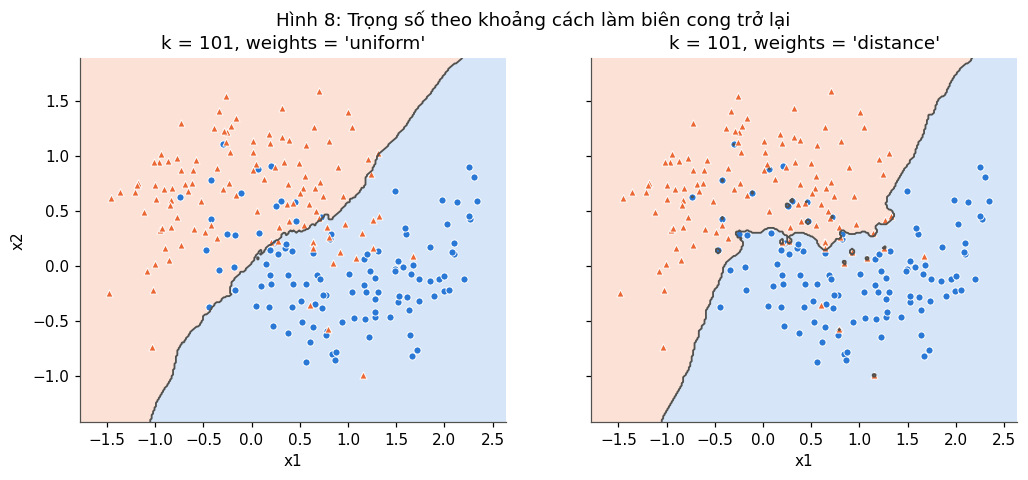

In [17]:
# Hình 8: biên quyết định với k = 101, phiếu đều và phiếu theo khoảng cách
khung = ((X["x1"].min() - 0.3, X["x1"].max() + 0.3), (X["x2"].min() - 0.3, X["x2"].max() + 0.3))
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, w in zip(axs, ["uniform", "distance"]):
    m = KNeighborsClassifier(n_neighbors=101, weights=w).fit(X_tr, y_tr)
    ve_bien(ax, m, X_tr, y_tr, ["x1", "x2"], khung)
    ax.set_title(f"k = 101, weights = '{w}'"); ax.set_xlabel("x1")
axs[0].set_ylabel("x2")
fig.suptitle("Hình 8: Trọng số theo khoảng cách làm biên cong trở lại"); plt.show()

**Nhận xét.** So với bảng ở mục 4 trên tập kiểm tra:

| k | phiếu đều | theo khoảng cách |
|---|---|---|
| 1 | 0.8000 | 0.8000 |
| 13 | 0.9200 | 0.9333 |
| 101 | 0.8533 | **0.9067** |

Với k = 1 hai cách giống hệt nhau, vì chỉ có một phiếu. Với k = 13 trọng số giúp thêm 1 mẫu. Với **k = 101** trọng số giúp rõ nhất: từ 0.8533 lên 0.9067, sửa đúng 4 mẫu đang sai và không làm hỏng mẫu nào.

**Có, trọng số giúp k = 101 bớt cẩu thả.** Với phiếu đều, mỗi trong 101 láng giềng nặng như nhau. Phần lớn chúng ở xa và thuộc vầng trăng bên kia, nên biên bị kéo thẳng ra (Hình 8 trái). Với phiếu nặng 1/khoảng cách, láng giềng gần nhất nặng gấp khoảng 15 lần láng giềng thứ 101 (trung vị), và 13 láng giềng gần nhất đã chiếm khoảng 37% tổng phiếu. Mô hình vì vậy hành xử gần giống KNN với k nhỏ, và biên cong lại theo hai vầng trăng (Hình 8 phải). Nói cách khác, trọng số khiến việc chọn k bớt nhạy: k lớn quá cũng không còn hại nhiều.

**Cái giá.** Cả ba dòng `distance` đều đạt 1.0000 trên tập học. Mỗi điểm học là láng giềng của chính nó với khoảng cách 0, tức trọng số vô cùng, nên nó luôn tự quyết định nhãn của mình. Ở Hình 8 phải thấy rõ điều này: quanh vài điểm học nằm lạc trong vùng lớp kia có một đốm viền đen rất nhỏ, là vùng mà điểm đó tự giữ nhãn của mình. Con số 1.0000 đó vô nghĩa giống k = 1 ở mục 4. Phải nhìn tập kiểm tra hoặc kiểm định chéo, không được nhìn tập học.

## Bài tập 5: Chọn k cho bài toán hồi quy
Kiểm định chéo 5 phần trên tập học để chọn k từ 1 tới 20 cho `KNeighborsRegressor` (`scoring="neg_mean_absolute_error"`), rồi so MAE tập kiểm tra với đường thẳng.

In [18]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# Cùng cách chia với e5_knn_hoi_quy.py
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42)
print(f"Tap hoc {len(X_tr)} can, tap kiem tra {len(X_te)} can")
print()

print("Kiem dinh cheo 5 phan tren tap hoc")
print("   k   MAE trung binh")
mae_cv = {}
for k in range(1, 21):
    diem = cross_val_score(KNeighborsRegressor(n_neighbors=k), X_tr, y_tr,
                           cv=5, scoring="neg_mean_absolute_error")
    mae_cv[k] = -diem.mean()
k_tot = min(mae_cv, key=mae_cv.get)
for k, m in mae_cv.items():
    dau = "  <- tot nhat" if k == k_tot else ""
    print(f"  {k:2d}   {m:.4f}{dau}")
print()

# Đường thẳng cũng được chấm bằng đúng cách đó để so trên cùng thước đo
mae_cv_duong = -cross_val_score(LinearRegression(), X_tr, y_tr, cv=5,
                                scoring="neg_mean_absolute_error").mean()
print(f"Duong thang, kiem dinh cheo: {mae_cv_duong:.4f}")
print()

knn = KNeighborsRegressor(n_neighbors=k_tot).fit(X_tr, y_tr)
knn5 = KNeighborsRegressor(n_neighbors=5).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)
print("MAE tren tap kiem tra (ty dong)")
print(f"  KNN, k = {k_tot:2d} (tot nhat): {mean_absolute_error(y_te, knn.predict(X_te)):.4f}")
print(f"  KNN, k =  5          : {mean_absolute_error(y_te, knn5.predict(X_te)):.4f}")
print(f"  Duong thang          : {mean_absolute_error(y_te, duong.predict(X_te)):.4f}")
print()

# Kiểm định chéo xáo trộn trước khi chia, để thấy k tốt nhất có vững không
print("Kiem dinh cheo co xao tron, doi random_state cua KFold")
for rs in range(5):
    cv = KFold(n_splits=5, shuffle=True, random_state=rs)
    m = {k: -cross_val_score(KNeighborsRegressor(n_neighbors=k), X_tr, y_tr,
                             cv=cv, scoring="neg_mean_absolute_error").mean()
         for k in range(1, 21)}
    kt = min(m, key=m.get)
    print(f"  random_state = {rs}: k tot nhat = {kt:2d}, MAE {m[kt]:.4f}")

Tap hoc 48 can, tap kiem tra 12 can

Kiem dinh cheo 5 phan tren tap hoc
   k   MAE trung binh


   1   0.4164
   2   0.3498  <- tot nhat
   3   0.3714
   4   0.3618
   5   0.3816
   6   0.4002
   7   0.3990
   8   0.4098
   9   0.4171
  10   0.4365
  11   0.4500
  12   0.4695
  13   0.4992
  14   0.5153
  15   0.5290
  16   0.5595
  17   0.5748
  18   0.5891
  19   0.6130
  20   0.6254

Duong thang, kiem dinh cheo: 0.3803

MAE tren tap kiem tra (ty dong)
  KNN, k =  2 (tot nhat): 0.4867
  KNN, k =  5          : 0.4030
  Duong thang          : 0.2578

Kiem dinh cheo co xao tron, doi random_state cua KFold


  random_state = 0: k tot nhat =  3, MAE 0.3723
  random_state = 1: k tot nhat =  2, MAE 0.3799


  random_state = 2: k tot nhat =  4, MAE 0.3446
  random_state = 3: k tot nhat =  2, MAE 0.3648


  random_state = 4: k tot nhat =  4, MAE 0.3682


**Nhận xét.** `cross_val_score` trả về **−MAE**, vì scikit-learn quy ước điểm càng lớn càng tốt. Mã đổi dấu trước khi so. Nếu quên dấu âm mà vẫn chọn k có điểm nhỏ nhất như thói quen với MAE, ta sẽ chọn nhầm k = 20, đúng k tệ nhất.

Kiểm định chéo chọn **k = 2** (MAE 0.3498). MAE tăng đều khi k vượt quá khoảng 5: k lớn thì mỗi dự đoán là trung bình của quá nhiều căn có diện tích khác xa, đường dự đoán bị san phẳng.

**Với k tốt nhất, KNN vẫn không vượt được đường thẳng.** Trên tập kiểm tra, KNN k = 2 có MAE **0.4867**, còn tệ hơn k = 5 của mục 6 (0.4030), trong khi đường thẳng đạt **0.2578**. Hai lý do:
- Quan hệ giá theo diện tích gần như thẳng, đúng giả định của hồi quy tuyến tính. KNN chỉ xấp xỉ đường đó bằng các bậc thang nên luôn có sai số do bậc.
- Tập học chỉ có 48 căn, mỗi phần kiểm định chéo chỉ khoảng 10 căn, nên điểm kiểm định chéo rất nhiễu. Xáo trộn lại cách chia 5 phần, k tốt nhất nhảy giữa 2, 3 và 4. Với k = 2, mỗi dự đoán chỉ dựa vào 2 căn nên dễ bị một căn có giá lệch kéo theo. Đó là lý do k = 2 thắng trong kiểm định chéo nhưng thua k = 5 trên 12 căn kiểm tra.

Phần kiểm định chéo cũng chấm luôn đường thẳng (0.3803). Con số này cao hơn KNN k = 2 trong kiểm định chéo, trái với kết quả trên tập kiểm tra, thêm một dấu hiệu rằng với 48 mẫu, so sánh nào cũng có sai số lớn. Kết luận vẫn là: với dữ liệu có quan hệ thật gần như thẳng, mô hình tham số đúng dạng thắng mô hình không tham số.

## Bài tập 6: Đo thời gian dự đoán
Tạo dữ liệu ngẫu nhiên 1 000, 10 000, 100 000 mẫu với 2 đặc trưng, đo thời gian `.fit` và `.predict` cho 1 000 mẫu mới.

In [19]:
import time

import numpy as np
from sklearn.neighbors import KNeighborsClassifier

rng = np.random.default_rng(0)
X_moi = rng.random((1000, 2))           # 1000 mẫu mới cần dự đoán
SO_LAN = 7                              # đo nhiều lần, lấy lần nhanh nhất


def do_thoi_gian(ham):
    """Tra ve thoi gian nhanh nhat (giay) qua SO_LAN lan chay."""
    ham()                               # chạy nháp một lần: lần đầu luôn chậm
    tot = float("inf")
    for _ in range(SO_LAN):
        bd = time.perf_counter()
        ham()
        tot = min(tot, time.perf_counter() - bd)
    return tot


# Chạy nháp cả hai cách một lượt cho máy "nóng" lên trước khi đo thật
for algo in ["brute", "auto"]:
    X = rng.random((20000, 2))
    mh = KNeighborsClassifier(n_neighbors=5, algorithm=algo).fit(X, X[:, 0] > 0.5)
    for _ in range(20):
        mh.predict(X_moi)

for algo in ["brute", "auto"]:
    print(f"algorithm = '{algo}', k = 5, du doan 1000 mau moi")
    print("     so mau      fit (ms)   predict (ms)   predict / fit")
    for n in [1000, 10000, 100000]:
        X = rng.random((n, 2))
        y = (X[:, 0] + X[:, 1] > 1).astype(int)
        mh = KNeighborsClassifier(n_neighbors=5, algorithm=algo)
        t_fit = do_thoi_gian(lambda: mh.fit(X, y))
        t_pre = do_thoi_gian(lambda: mh.predict(X_moi))
        print(f"  {n:9d}   {t_fit * 1000:10.2f}   {t_pre * 1000:12.2f}"
              f"   {t_pre / t_fit:12.0f}")
    print()

algorithm = 'brute', k = 5, du doan 1000 mau moi
     so mau      fit (ms)   predict (ms)   predict / fit
       1000         0.19           2.57             13
      10000         0.32           8.85             27


     100000         1.96          47.10             24

algorithm = 'auto', k = 5, du doan 1000 mau moi
     so mau      fit (ms)   predict (ms)   predict / fit
       1000         0.31          13.99             44


      10000         1.78          13.75              8


     100000        21.37          13.69              1



**Nhận xét.** Đo trên MacBook (8 nhân), lấy lần nhanh nhất trong 7 lần sau khi đã chạy nháp. Con số tuyệt đối tuỳ máy, chỉ so tương đối.

Với `algorithm="brute"`, đúng là KNN thuần như mô tả ở mục 2:
- `.fit` gần như bằng 0 (vài phần mười mili giây) và gần như không đổi khi dữ liệu tăng 100 lần. Nó chỉ kiểm tra rồi cất mảng vào bộ nhớ.
- `.predict` tăng theo số mẫu, khoảng 2 → 7 → 50 ms, vì mỗi mẫu mới phải tính khoảng cách tới **mọi** mẫu đã cất. Từ 10 000 lên 100 000 mẫu thì tăng khoảng 7 lần, gần tỷ lệ thuận. Ở cỡ nhỏ, chi phí cố định che mất một phần.
- `.predict` chậm hơn `.fit` từ khoảng 10 tới 25 lần.

Đó là lý do KNN được gọi là **mô hình học lười**: lúc học không làm gì, mọi phép tính dồn sang lúc dự đoán, và dữ liệu càng lớn thì dự đoán càng chậm. Ngược hẳn với hồi quy tuyến tính hay Naive Bayes: học một lần, cô dữ liệu thành vài con số, nên dự đoán gần như tức thì và không phụ thuộc cỡ tập học.

**Chuyện ngoài lề với `algorithm="auto"` (mặc định).** Với 2 đặc trưng, scikit-learn tự dựng một cây k-d lúc `.fit` để tìm láng giềng nhanh hơn. Thời gian `.fit` lúc này tăng theo dữ liệu (khoảng 0.3 → 1.8 → 21 ms), còn `.predict` gần như đứng yên khoảng 14 ms. Ở cỡ nhỏ, `.predict` chậm hơn brute vì chi phí cố định khi duyệt cây. Thư viện đã "lười bớt" bằng cách làm trước một ít việc lúc học, nhưng `.predict` vẫn phải giữ và tra toàn bộ dữ liệu. Cây k-d cũng chỉ hiệu quả khi ít chiều, nên không cứu được lời nguyền số chiều ở Hình 6.